# BijliPredict AI - Exploration

Lightweight EDA for the daily household electricity consumption series.
Run the pipeline first: `python generate_data.py` (or `python iawe_ingest.py`),
then `python train.py`, `python evaluate.py` and `python predict.py` so the
files under `outputs/` and `artifacts/` exist.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Allow importing top-level project modules from the notebook, whether it
# is launched from the project root or from the notebooks/ directory.
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "preprocessing.py").exists():
        sys.path.append(str(_p))
        break
from preprocessing import clean_series, load_consumption

plt.rcParams["figure.figsize"] = (12, 4)
pd.set_option("display.width", 120)

## 1. Load and clean

In [2]:
DATA = "../data/processed/daily_consumption.csv"
series = clean_series(load_consumption(DATA))
series.describe()

,consumption_kwh
count,1095.000000
mean,5.169223
std,1.723771
min,0.909000
25%,3.835000
50%,4.914000
75%,6.527500
max,10.266000


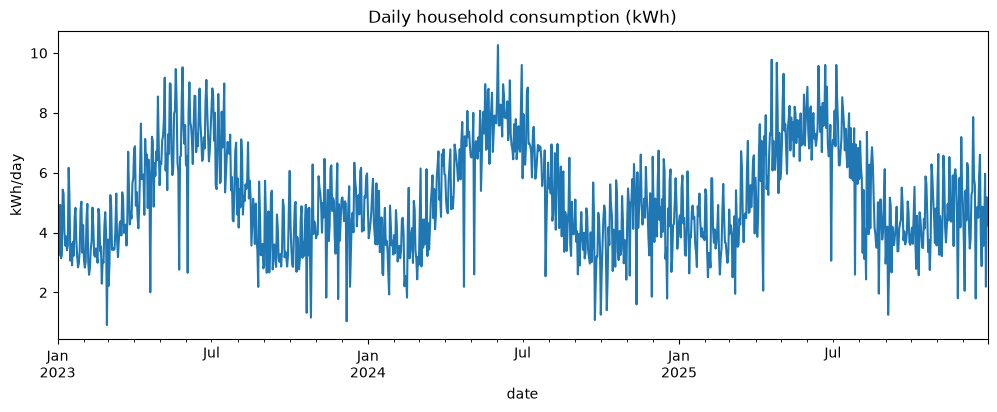

In [3]:
series["consumption_kwh"].plot(title="Daily household consumption (kWh)")
plt.ylabel("kWh/day")
plt.show()

## 2. Weekly pattern

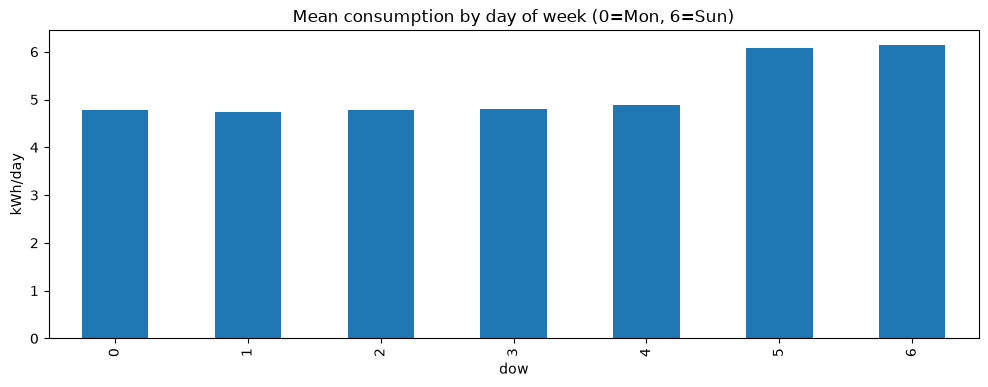

In [4]:
df = series.copy()
df["dow"] = df.index.dayofweek
df.groupby("dow")["consumption_kwh"].mean().plot(
    kind="bar", title="Mean consumption by day of week (0=Mon, 6=Sun)"
)
plt.ylabel("kWh/day")
plt.show()

## 3. Annual / monthly pattern

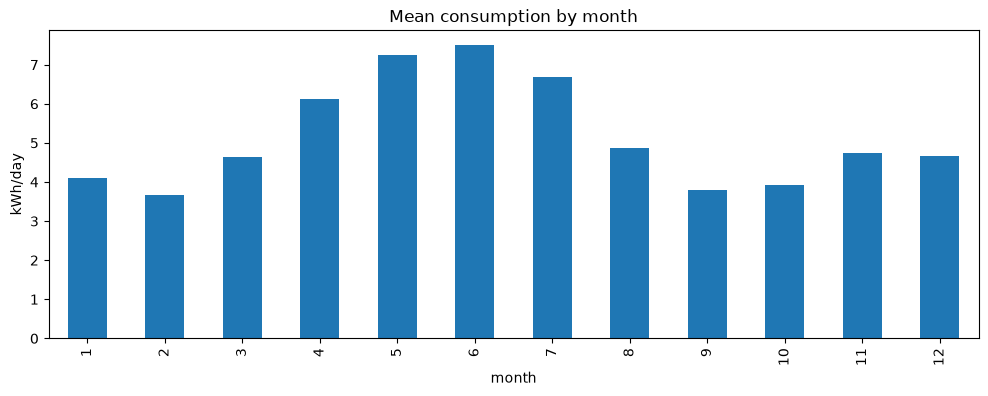

In [5]:
df["month"] = df.index.month
df.groupby("month")["consumption_kwh"].mean().plot(
    kind="bar", title="Mean consumption by month"
)
plt.ylabel("kWh/day")
plt.show()

## 4. Missingness / gaps in the source file

In [6]:
raw = load_consumption(DATA)
expected = pd.date_range(raw.index.min(), raw.index.max(), freq="D")
print("rows:", len(raw), " expected daily:", len(expected), " missing:", len(expected) - len(raw))
print("min/max:", float(raw["consumption_kwh"].min()), float(raw["consumption_kwh"].max()))

rows: 1095  expected daily: 1095  missing: 0
min/max: 0.909 10.266


## 5. Trained model results

After running `python train.py` and `python evaluate.py`, inspect the saved
metrics and plot.

{
  "mae": 0.6629570021581809,
  "rmse": 0.9067322082946118,
  "wape": 15.005369204222863,
  "mape": 19.248675679041238
}
vs seasonal-naive: {'mae': 0.9193765113784097, 'rmse': 1.2132065798346914, 'wape': 20.8091685373463, 'mape': 25.409487545022486}


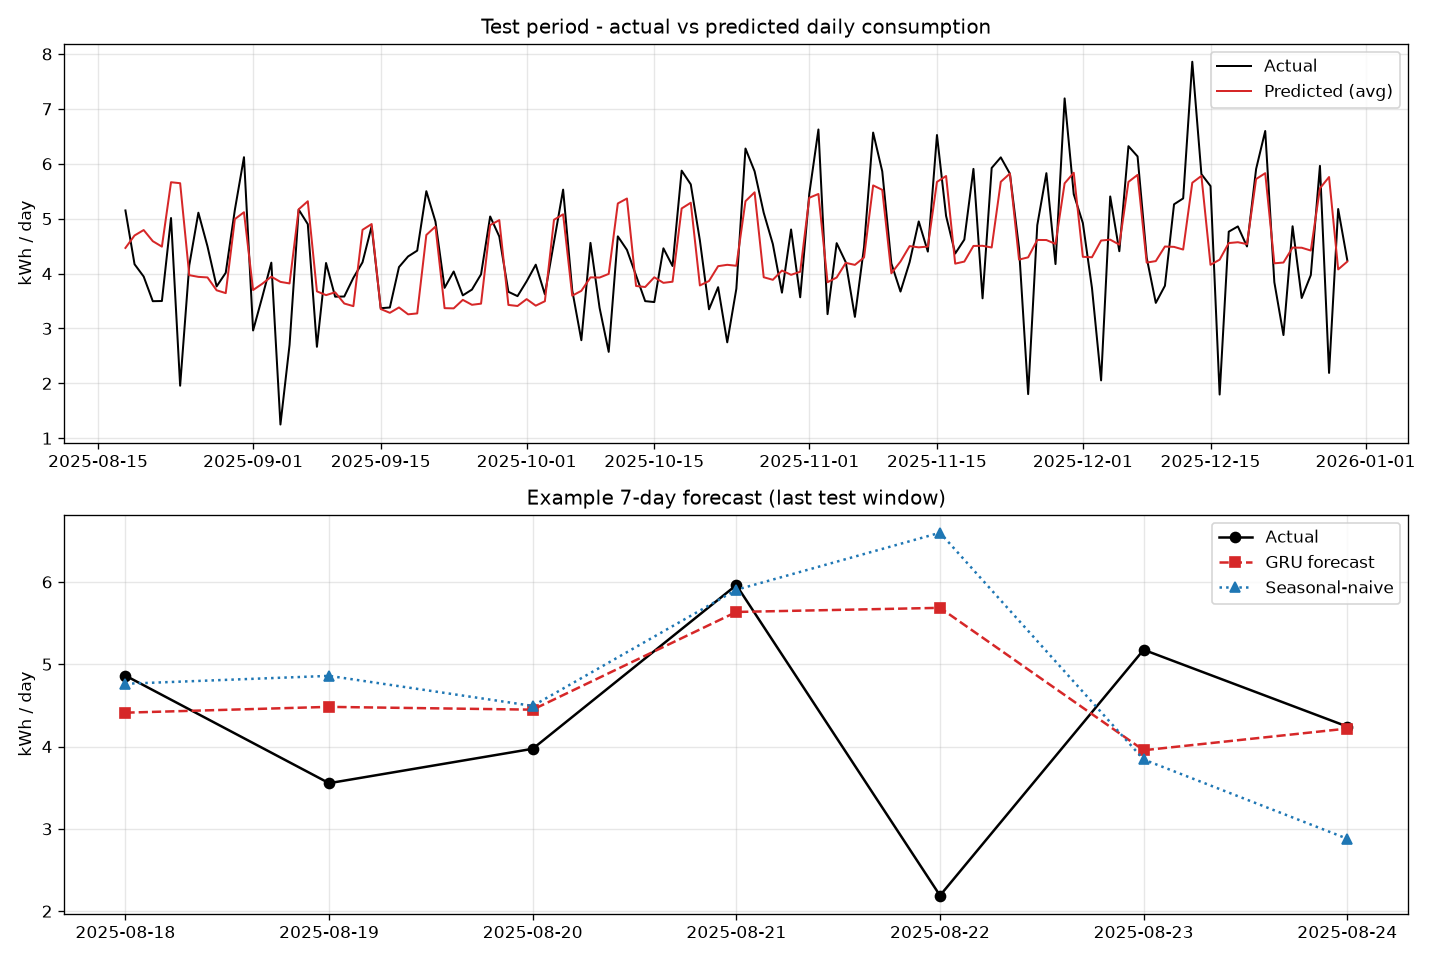

In [7]:
import json
from IPython.display import Image

results = json.loads(Path("../outputs/evaluation.json").read_text())
print(json.dumps(results["model_metrics"], indent=2))
print("vs seasonal-naive:", results["baseline_metrics"]["seasonal_naive_p7"])
Image(filename="../outputs/forecast.png")

## 6. Forecast and cost prediction

`predict.py` forecasts the next 7 days of consumption and converts them to a
bill using the `tariffs.py` module (flat rate or progressive Indian slabs,
plus optional fixed charge and tax). Run `python predict.py` first so the
files below exist.

In [8]:
from IPython.display import Image

cost = json.loads(Path("../outputs/cost_summary.json").read_text())
print("Tariff:", cost["tariff"])
print(f"Forecast : {cost['total_kwh']} kWh over {cost['forecast_days']} days")
print(f"Energy   : Rs {cost['energy_charge_inr']}")
print(f"Tax      : Rs {cost['tax_inr']}")
print(f"Fixed    : Rs {cost['fixed_charge_inr']}")
print(f"TOTAL    : Rs {cost['estimated_bill_inr']}")
pd.DataFrame(cost["daily"])

Tariff: ₹5/kWh (flat)
Forecast : 24.504 kWh over 7 days
Energy   : Rs 122.52
Tax      : Rs 0.0
Fixed    : Rs 0.0
TOTAL    : Rs 122.52


,date,kwh,cost_inr
0,2025-12-31,2.985,14.92
1,2026-01-01,3.156,15.78
2,2026-01-02,4.112,20.56
3,2026-01-03,4.586,22.93
4,2026-01-04,3.500,17.50
5,2026-01-05,3.002,15.01
6,2026-01-06,3.163,15.81


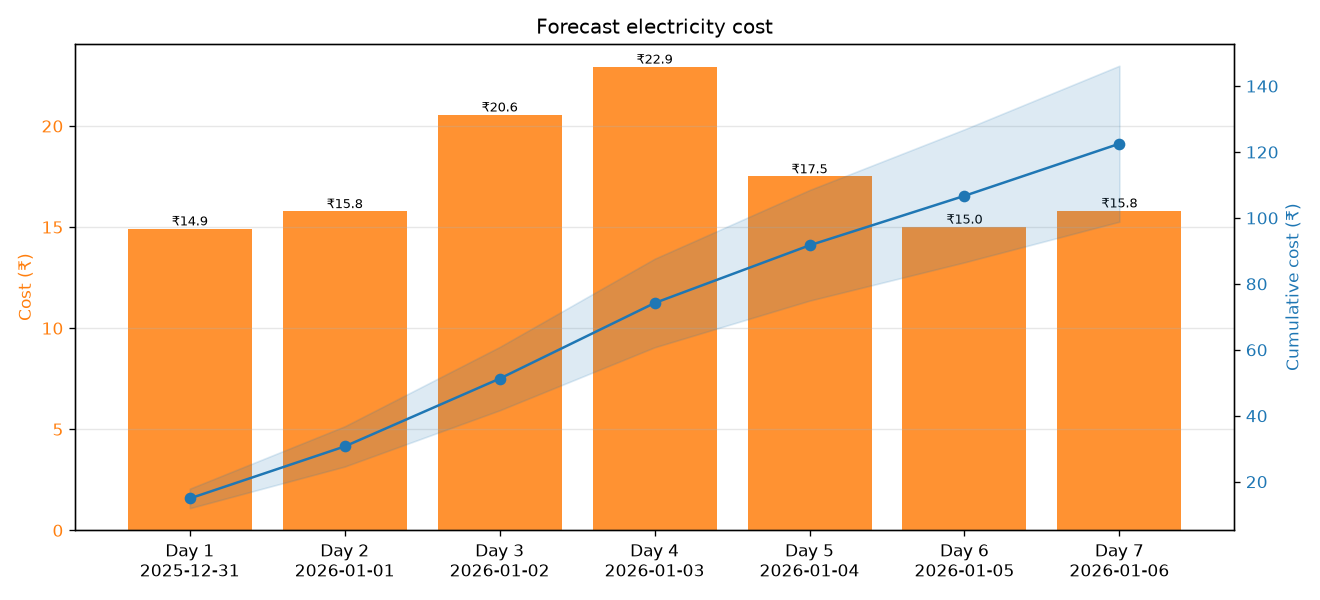

In [9]:
Image(filename="../outputs/cost_forecast.png")

### Compare tariffs for the same forecast

The model predicts consumption; the tariff only changes the money. Here we
re-price the forecast under a flat rate and a typical slab tariff.

In [10]:
import sys
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "tariffs.py").exists():
        sys.path.append(str(_p))
        break
from tariffs import Tariff, compute_bill, parse_slabs

forecast_kwh = [d["kwh"] for d in cost["daily"]]

flat = Tariff(rate=7.0)
slab = Tariff(
    slabs=parse_slabs("0-100:3.5,100-200:4.5,200-400:6.5,400-100000:7"),
    fixed=50.0,
    tax_pct=5.0,
)

for name, t in (("flat Rs7/kWh", flat), ("slab + Rs50 + 5% tax", slab)):
    b = compute_bill(forecast_kwh, t)
    print(f"{name:>24}: Rs {b['total']:.2f}  ({b['total_kwh']:.1f} kWh)")

            flat Rs7/kWh: Rs 171.53  (24.5 kWh)
    slab + Rs50 + 5% tax: Rs 140.05  (24.5 kWh)


### Monthly & 3-month cost projection

`predict.py` rolls the model forward **autoregressively** (`--project-days`,
default 90) to estimate a monthly (30-day) and 3-month (90-day) bill. Long
horizons compound model error, so treat these as directional estimates.

 Monthly (30d):    107.0 kWh   Rs 534.79
 3-Month (90d):    327.5 kWh   Rs 1637.32


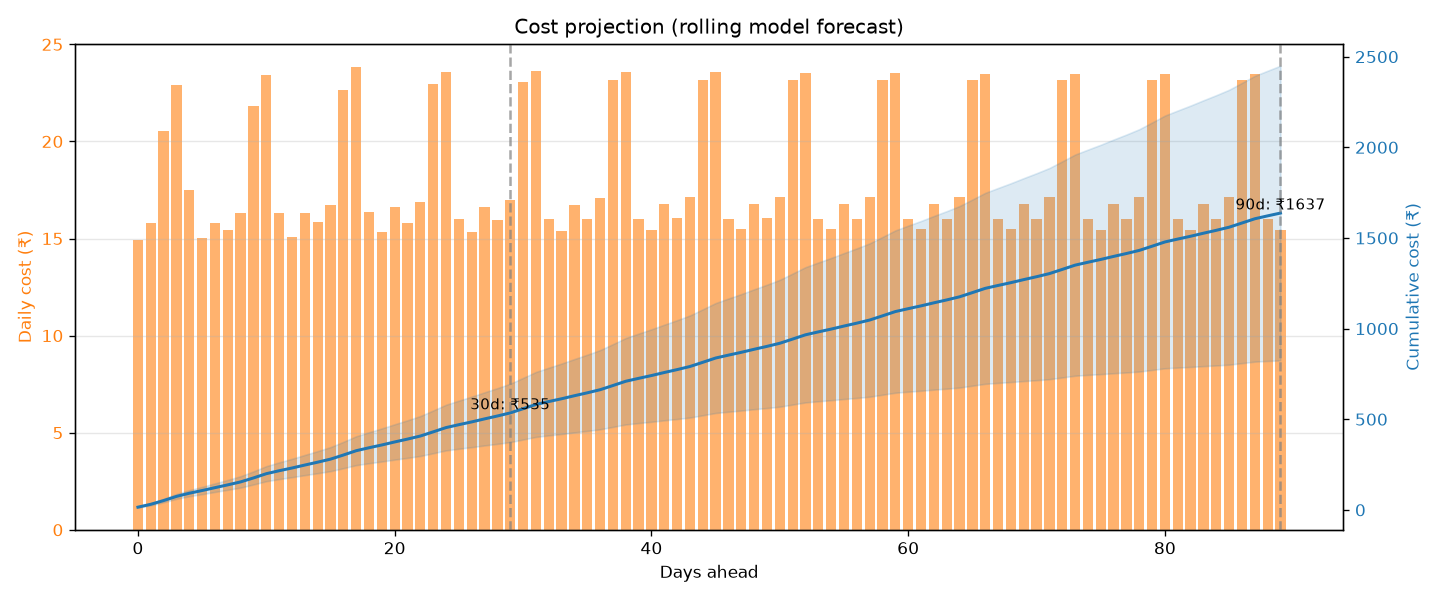

In [11]:
proj = json.loads(Path("../outputs/cost_summary.json").read_text())["projection"]
for label, key in (("Monthly (30d)", "monthly_30d"), ("3-Month (90d)", "three_month_90d")):
    p = proj[key]
    print(f"{label:>14}: {p['total_kwh']:8.1f} kWh   Rs {p['estimated_bill_inr']:.2f}")
Image(filename="../outputs/cost_projection.png")

In [12]:
proj_csv = pd.read_csv("../outputs/projection_90d.csv")
print("projected days:", len(proj_csv))
proj_csv.head()

projected days: 90


,date,projected_kwh,lower_80,upper_80,lower_90,upper_90,daily_cost_inr,cumulative_cost_inr
0,2025-12-31,2.985,2.393,3.577,2.167,3.802,14.92,14.92
1,2026-01-01,3.156,2.527,3.784,2.298,4.014,15.78,30.70
2,2026-01-02,4.112,3.411,4.813,3.118,5.105,20.56,51.26
3,2026-01-03,4.586,3.822,5.350,3.487,5.685,22.93,74.19
4,2026-01-04,3.500,2.831,4.170,2.540,4.461,17.50,91.69


### Downloadable Excel report

A single multi-sheet workbook (`Summary`, `Forecast`, `Projection`,
`Evaluation`, `Tariff`) is assembled from the pipeline outputs and offered
for download.

In [13]:
import sys
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "report.py").exists():
        sys.path.append(str(_p))
        break
from report import build_excel
from IPython.display import FileLink, display

xlsx = build_excel("../outputs", "../outputs/bijli_report.xlsx")
print("Workbook:", xlsx.resolve())
with pd.ExcelFile(xlsx) as xl:
    print("Sheets:", xl.sheet_names)
    display(xl.parse("Summary"))
display(FileLink(str(xlsx)))

Workbook: /home/mikey2006/CODING/AIML/LEARNING/NEURAL NETWORKS/bijli-predict-ai/outputs/bijli_report.xlsx
Sheets: ['Summary', 'Forecast', 'Projection', 'Evaluation', 'Tariff']


,Item,Value
0,Generated,2026-10-14 21:37
1,Model,GRU
2,Tariff,₹5/kWh (flat)
3,NaN,NaN
4,7-day forecast (kWh),24.5
5,7-day estimated bill (INR),122.52
6,7-day bill 80% band (INR),98.87 – 146.17
7,7-day bill 90% band (INR),89.2 – 155.83
8,Monthly 30d (kWh),106.96
9,Monthly 30d bill (INR),534.79


/home/mikey2006/CODING/AIML/LEARNING/NEURAL NETWORKS/bijli-predict-ai/outputs/bijli_report.xlsx

## 7. Prediction intervals (conformal)

`evaluate.py` fits a **level-scaled split-conformal** calibration on the
validation split (`artifacts/calibration.json`). For each horizon the
nonconformity scores are rescaled by `sigma(y_hat) = y_hat ** gamma`, so the
band widens where the load is high. `predict.py` applies the quantiles to
emit 80% and 90% intervals on the 7-day forecast (and rescaled versions for
the projected totals).

In [14]:
cal = json.loads(Path("../artifacts/calibration.json").read_text())
print("method:", cal["method"], "| scale:", cal["scale"], "| gamma:", cal["gamma"])
print("horizon:", cal["horizon"], "| calibration windows:", cal["n_cal"])
for level, q in cal["levels"].items():
    print(f"  {float(level):.0%}: per-day quantiles h=1..{len(q)} {[round(x, 3) for x in q]}")

cov = json.loads(Path("../outputs/evaluation.json").read_text())["calibration"]["coverage"]
for lvl, d in cov.items():
    print(f"  nominal {float(lvl):.0%} -> empirical {d['empirical']:.1%} (mean width {d['mean_width']:.2f} kWh)")

method: split-conformal-normalized | scale: power | gamma: 0.5
horizon: 7 | calibration windows: 128
  80%: per-day quantiles h=1..7 [0.4, 0.394, 0.354, 0.412, 0.395, 0.393, 0.394]
  90%: per-day quantiles h=1..7 [0.565, 0.53, 0.498, 0.549, 0.563, 0.553, 0.556]
  nominal 80% -> empirical 72.2% (mean width 1.64 kWh)
  nominal 90% -> empirical 84.8% (mean width 2.28 kWh)


In [15]:
preds = pd.read_csv("../outputs/predictions.csv")
preds[["date", "predicted_kwh", "lower_80", "upper_80", "lower_90", "upper_90"]]

,date,predicted_kwh,lower_80,upper_80,lower_90,upper_90
0,2025-12-31,2.985,2.393,3.577,2.167,3.802
1,2026-01-01,3.156,2.527,3.784,2.298,4.014
2,2026-01-02,4.112,3.411,4.813,3.118,5.105
3,2026-01-03,4.586,3.822,5.350,3.487,5.685
4,2026-01-04,3.500,2.831,4.170,2.540,4.461
5,2026-01-05,3.002,2.323,3.681,2.086,3.918
6,2026-01-06,3.163,2.467,3.859,2.144,4.181


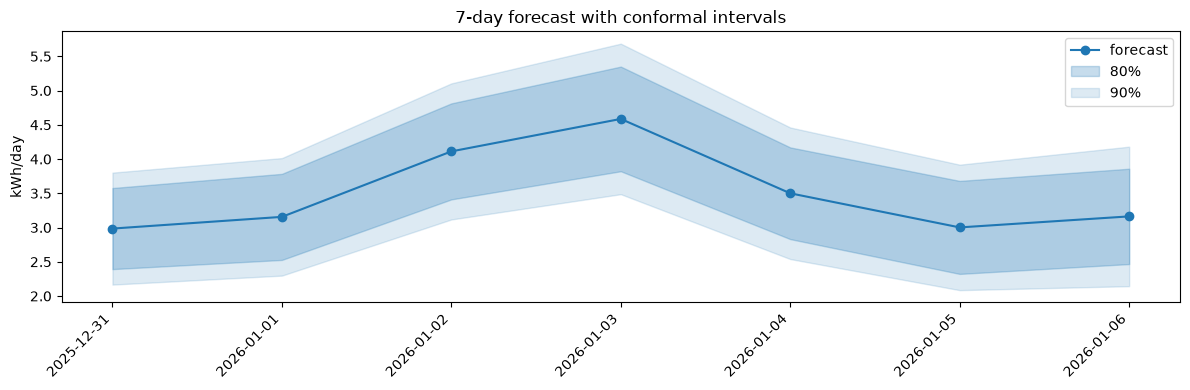

In [16]:
fig, ax = plt.subplots()
x = list(range(len(preds)))
ax.plot(x, preds["predicted_kwh"], marker="o", color="C0", label="forecast")
ax.fill_between(x, preds["lower_80"], preds["upper_80"], alpha=0.25, color="C0", label="80%")
ax.fill_between(x, preds["lower_90"], preds["upper_90"], alpha=0.15, color="C0", label="90%")
ax.set_xticks(x)
ax.set_xticklabels(preds["date"], rotation=45, ha="right")
ax.set_ylabel("kWh/day")
ax.set_title("7-day forecast with conformal intervals")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Rolling-origin CV & statistical baselines

`evaluate.py --cv rolling` re-scores the model on expanding-window origins and
stores per-fold metrics in `outputs/evaluation_cv.json`. The same run compares
against naive baselines (persistence, seasonal-naive) and, with the `stats`
extra, SARIMAX / Holt-Winters ETS — the honest question being whether the GRU
actually beats a simple weekly model.

In [17]:
cv = json.loads(Path("../outputs/evaluation_cv.json").read_text())
print(f"{cv['method']}: {cv['n_folds']} folds, min train size {cv['min_train_size']}")
print(f"WAPE {cv['wape_mean']:.2f}% +/- {cv['wape_std']:.2f}%")
pd.DataFrame([{"fold": f["fold"], **f["metrics"]} for f in cv["folds"]]).round(3)

rolling-origin: 3 folds, min train size 1163
WAPE 10.95% +/- 0.58%


,fold,mae,rmse,wape,mape
0,0,0.633,0.862,10.202,10.994
1,1,0.782,1.075,11.027,12.636
2,2,0.688,0.925,11.623,15.141


In [18]:
ev = json.loads(Path("../outputs/evaluation.json").read_text())
rows = {"gru": ev["model_metrics"], **ev["baseline_metrics"]}
pd.DataFrame(rows).T[["mae", "rmse", "wape", "mape"]].round(3)

,mae,rmse,wape,mape
gru,0.663,0.907,15.005,19.249
seasonal_naive_p7,0.919,1.213,20.809,25.409
persistence,1.239,1.576,28.036,32.600


### Downloadable HTML report

`report.py` also renders a self-contained HTML summary (headline numbers,
the 7-day forecast with intervals, the projection and the evaluation table).
It is written by `python predict.py` (`--html-out`) or by `report.py`.

In [19]:
import sys
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "report.py").exists():
        sys.path.append(str(_p))
        break
from report import build_html
from IPython.display import FileLink, display

html = build_html("../outputs", "../outputs/bijli_report.html")
print("HTML report:", html.resolve())
display(FileLink(str(html)))

HTML report: /home/mikey2006/CODING/AIML/LEARNING/NEURAL NETWORKS/bijli-predict-ai/outputs/bijli_report.html


/home/mikey2006/CODING/AIML/LEARNING/NEURAL NETWORKS/bijli-predict-ai/outputs/bijli_report.html

## 9. Input validation & run manifests

Every command validates its input CSV first — malformed files fail with a
friendly, row-annotated message — and writes a JSON **manifest** recording the
command, arguments, git revision, input hashes and durations under
`outputs/manifests/`. Here we validate the series and inspect the latest run.

In [20]:
import sys
for _p in [Path.cwd(), *Path.cwd().parents]:
    if (_p / "validation.py").exists():
        sys.path.append(str(_p))
        break
from validation import validate_consumption_frame, validation_to_dataframe

report = validate_consumption_frame(pd.read_csv(DATA), "date", "consumption_kwh", strict=False)
print("valid:", report.ok, "| engine:", report.schema_engine, "| rows:", report.n_rows)
validation_to_dataframe(report)

valid: True | engine: pandera | rows: 1095


,check,status,count
0,rows,ok,0
1,bad_dates,ok,0
2,bad_values,ok,0
3,missing_dates,ok,0
4,missing_values,ok,0
5,negative_values,ok,0
6,duplicate_dates,ok,0


In [21]:
manifests = sorted(Path("../outputs/manifests").glob("*.json"))
latest = json.loads(manifests[-1].read_text())
print("latest manifest:", manifests[-1].name)
headline = {k: latest[k] for k in ("command", "status", "started_at", "duration_s", "git")}
print(json.dumps(headline, indent=2))
print("inputs:", {k: v.get("sha256", "")[:12] for k, v in latest.get("inputs", {}).items()})

latest manifest: tune_20261014T155335Z.json
{
  "command": "tune",
  "status": "ok",
  "started_at": "2026-10-14T15:49:29Z",
  "duration_s": 245.112,
  "git": {
    "sha": "28630b567e8c324ac68216eb156941734ad0c94f",
    "dirty": true
  }
}
inputs: {'data': '7ed01354c55c'}
